In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("libraries imported")

libraries imported


In [5]:
df = pd.read_excel("D:/python final project(saran)/online_retail_II.xlsx",sheet_name ="Year 2010-2011" )
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
#understand the data
print("rows and columns:", df.shape)
print("column names:",list(df.columns))

rows and columns: (541910, 8)
column names: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [7]:
#data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[us]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [8]:
#data cleaning
#missing values
print("checking the missing value")
print(df.isnull().sum())
df["Description"] = df["Description"].fillna("unknown")
df["Customer ID"] = df["Customer ID"].fillna(0)
print(df.isnull().sum())

checking the missing value
Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


In [9]:
#duplicate rows
print("duplicate rows:",df.duplicated().sum())
df = df.drop_duplicates()
print("rows after removing duplicates:",len(df))

duplicate rows: 5268
rows after removing duplicates: 536642


In [10]:

#cancelled orders
cancelled = df["Invoice"].astype(str).str.startswith("C")
print("cancelled rows:", cancelled.sum())
df = df[~cancelled]
print("rows after removing cancelled orders:", len(df))

cancelled rows: 9251
rows after removing cancelled orders: 527391


In [11]:
#zero or negative values
print("zero/negative quantity:", (df["Quantity"] <= 0).sum())
print("zero/negative price:", (df["Price"] <= 0).sum())

zero/negative quantity: 1336
zero/negative price: 2512


In [12]:
#remove zero or negative rows
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
print("rows after removing them:", len(df))

rows after removing them: 524879


In [13]:
df = df[~df["Quantity"].isin([80995,74215])]
print("largest Quantity now:", df["Quantity"].max())


largest Quantity now: 4800


In [14]:
#create the revenue column
df["revenue"] = df["Price"] * df["Quantity"]
print("total revenue:",round(df["revenue"].sum()))
df.to_csv('cleaned_dataset.csv', index = False)
df.head()

total revenue: 10396476


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [15]:
#data transformation
df["Month"] = df["InvoiceDate"].dt.strftime("%Y-%m")
print(df["Month"].unique())
df[["InvoiceDate", "Month"]].head()

<StringArray>
['2010-12', '2011-01', '2011-02', '2011-03', '2011-04', '2011-05', '2011-06',
 '2011-07', '2011-08', '2011-09', '2011-10', '2011-11', '2011-12']
Length: 13, dtype: str


,InvoiceDate,Month
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [16]:
#EDA - summary of numbers
print(df[["Quantity", "Price", "revenue"]].describe())

#top 10 countries by revenue
top_countries = df.groupby("Country")["revenue"].sum().sort_values(ascending=False).head(10)
print("\nTop 10 countries by revenue:")
print(top_countries)

#top 10 products by quantity sold
top_products = df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
print("\nTop 10 products by quantity:")
print(top_products)

#revenue by month
monthly_revenue = df.groupby("Month")["revenue"].sum()
print("\nRevenue by month:")
print(monthly_revenue)

            Quantity          Price        revenue
count  524877.000000  524877.000000  524877.000000
mean       10.320915       3.922608      19.807451
std        37.914131      36.093067      91.720350
min         1.000000       0.001000       0.001000
25%         1.000000       1.250000       3.900000
50%         4.000000       2.080000       9.920000
75%        11.000000       4.130000      17.700000
max      4800.000000   13541.330000   38970.000000

Top 10 countries by revenue:
Country
United Kingdom    8756090.894
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209643.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: revenue, dtype: float64

Top 10 products by quantity:
Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872

In [17]:
#descriptive statistics
print("Revenue mean:", round(np.mean(df["revenue"]), 2))
print("Revenue median:", round(df["revenue"].median(), 2))
print("Revenue std:", round(np.std(df["revenue"]), 2))

print("Quantity mean:", round(np.mean(df["Quantity"]), 2))
print("Quantity median:", df["Quantity"].median())
print("Quantity max:", np.max(df["Quantity"]))

Revenue mean: 19.81
Revenue median: 9.92
Revenue std: 91.72
Quantity mean: 10.32
Quantity median: 4.0
Quantity max: 4800


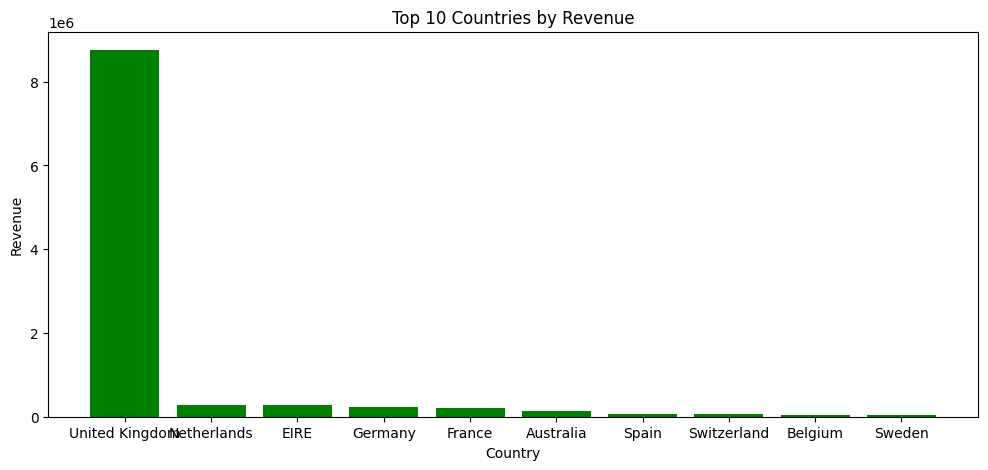

In [18]:
#chart 1 - top 10 countries by revenue
plt.figure(figsize=(12, 5))
plt.bar(top_countries.index, top_countries.values, color="green")
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.show()

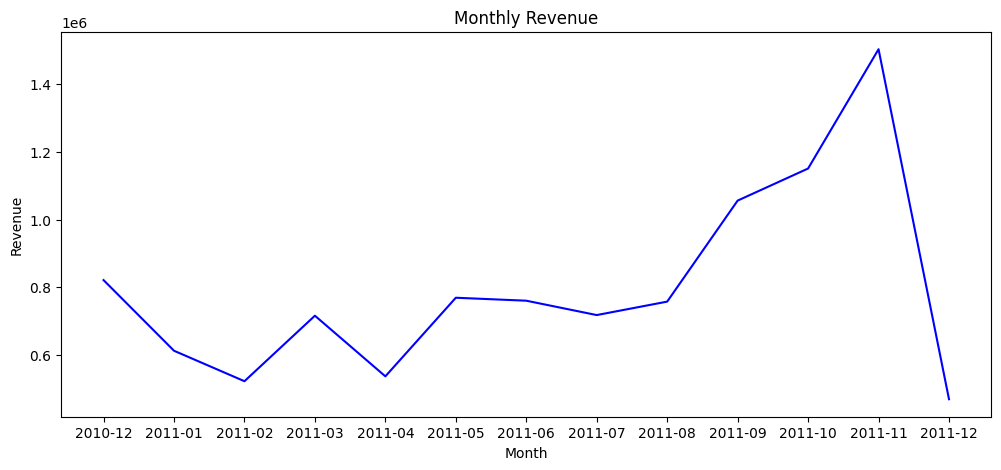

In [19]:
#chart 2 - monthly revenue trend
plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, color="blue")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

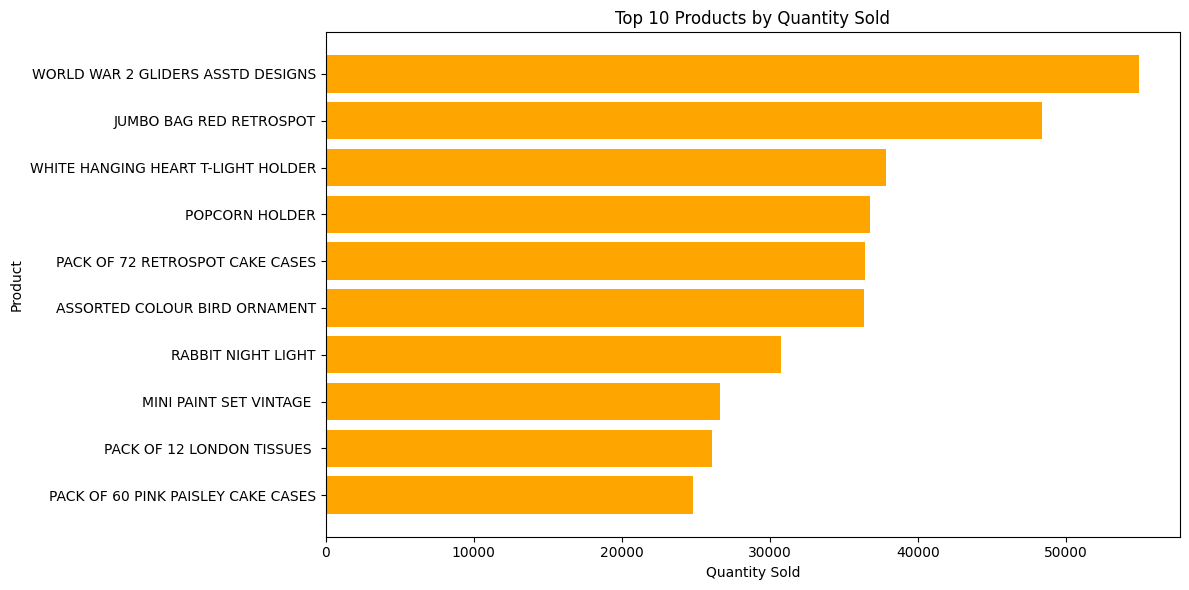

In [20]:
#chart 3 - top 10 products by quantity sold
products_sorted = top_products.sort_values()

plt.figure(figsize=(12, 6))
plt.barh(products_sorted.index, products_sorted.values, color="orange")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

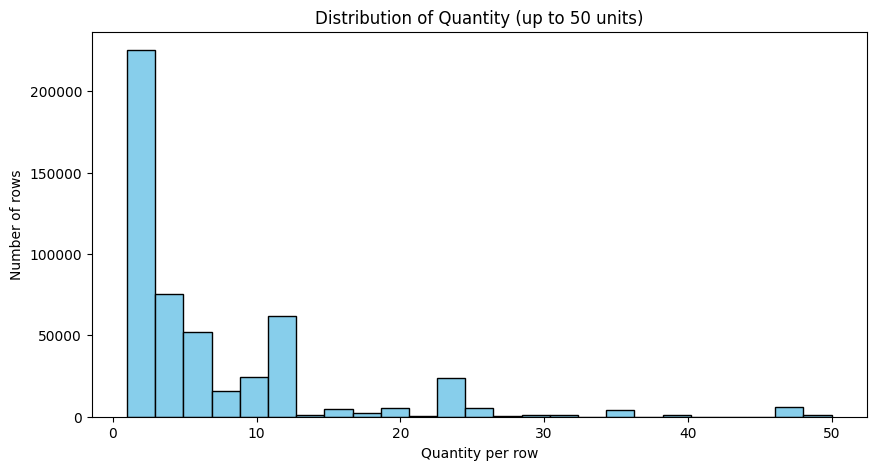

In [21]:
#chart 4 - distribution of quantity (orders up to 50 units)
small_orders = df[df["Quantity"] <= 50]

plt.figure(figsize=(10, 5))
plt.hist(small_orders["Quantity"], bins=25, color="skyblue", edgecolor="black")
plt.title("Distribution of Quantity (up to 50 units)")
plt.xlabel("Quantity per row")
plt.ylabel("Number of rows")
plt.show()

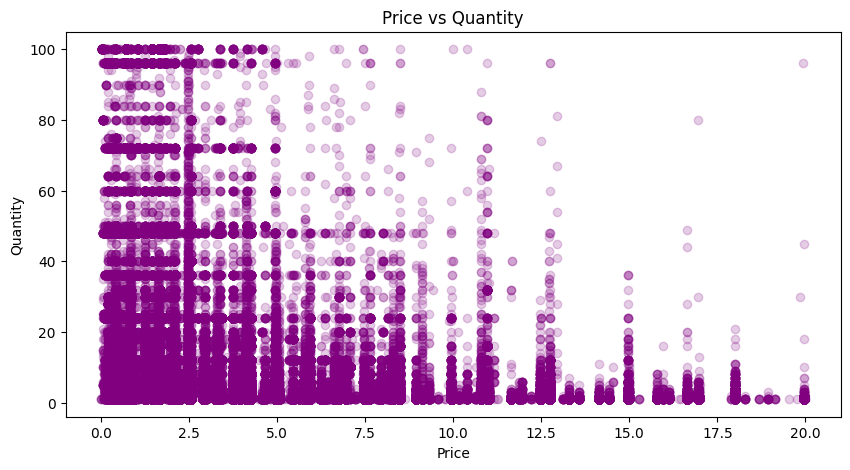

In [22]:
#chart 5 - price vs quantity (price up to 20, quantity up to 100)
plot_data = df[(df["Price"] <= 20) & (df["Quantity"] <= 100)]

plt.figure(figsize=(10, 5))
plt.scatter(plot_data["Price"], plot_data["Quantity"], color="purple", alpha=0.2)
plt.title("Price vs Quantity")
plt.xlabel("Price")
plt.ylabel("Quantity")
plt.show()

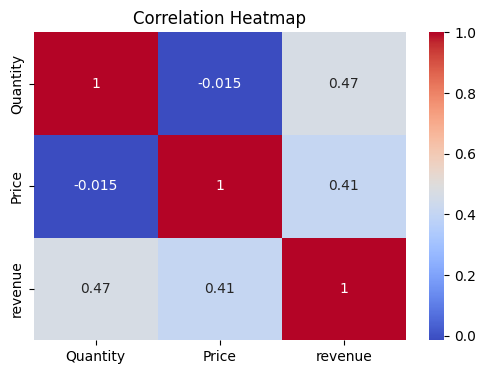

In [23]:
#chart 6 - correlation heatmap
correlation = df[["Quantity", "Price", "revenue"]].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Business Insights

1. **The business depends on the UK.** The United Kingdom brings in about 8.76 million of the 10.4 million total revenue (about 84%). The next markets, the Netherlands, Ireland (EIRE), Germany and France, each bring in only 200-285 thousand.
2. **Sales peak before Christmas.** Revenue rises from September (1.06M) to a peak in November (1.50M). September to November alone make up about 37% of revenue from Dec 2010 to Nov 2011. December 2011 looks low only because the data ends on 9 December.
3. **Most orders are small, but a few are very large.** About 98% of rows are 50 units or fewer, while the largest is 4,800. The average revenue per row (19.81) is about double the median (9.92), so a few bulk orders pull the average up.
4. **Cheap, small items are the best sellers.** The top products by quantity are World War 2 Gliders, Jumbo Bag Red Retrospot, White Hanging Heart T-Light Holder, and several cake case packs.
5. **Price does not decide how much is bought.** The correlation between Price and Quantity is almost zero (-0.02). Revenue is moderately related to both Quantity (0.47) and Price (0.41).

# Conclusion and Recommendations

The analysis shows a UK-focused wholesale gift business with a strong pre-Christmas season and many small, low-priced orders.

**Recommendations**
- Stock up and plan promotions before September, because sales rise sharply from September to November.
- Keep best-selling products well stocked, especially cake cases, bags and light holders.
- Offer bulk-order discounts, since a few large orders add a lot of revenue.
- Grow the next markets (Netherlands, Ireland, Germany, France) to reduce dependence on the UK.
- Record customer details more carefully, because about 132 thousand rows had no Customer ID.

**Limitations:** the data ends on 9 December 2011, and some rows are fees such as postage rather than products.